# Stock Market Dashboard: walkthrough

This walkthrough runs the whole pipeline from top to bottom:

1. **Fetch** five years of daily prices from Yahoo Finance
2. **Clean** the data
3. **Enrich** it with technical indicators
4. **Chart** each indicator
5. **Combine** the charts and KPI cards into one dashboard page

Every step calls the same functions in `src/` that build the Power BI data
and the PDF summaries, so the numbers here match the dashboard.

It needs an internet connection (Yahoo Finance is free and needs no API key)
and takes under a minute. Run it as a script from the project folder:

```
python deliverables/walkthrough.py
```

The notebook `walkthrough.ipynb` holds the same steps with their output
saved. Nothing rebuilds one from the other, so change both together.

## Setup

Imports, the tickers to analyse, and a helper that saves each chart.

In [1]:
import datetime as dt
import html
import sys
from pathlib import Path

# Find the project folder (the one holding src/config.py), so the imports below
# work from the script, from Jupyter, and from any folder inside the project.
_start = Path(__file__).resolve() if "__file__" in globals() else Path.cwd()
ROOT = next(
    (p for p in (_start, *_start.parents) if (p / "src" / "config.py").is_file()),
    None,
)
if ROOT is None:
    raise SystemExit("Run this from inside the project folder.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

# A Windows console that cannot print the rupee sign should not stop the run.
if hasattr(sys.stdout, "reconfigure"):
    sys.stdout.reconfigure(errors="replace")

import pandas as pd
import plotly.io as pio

from src import charts, config
from src.data.cleaner import clean_ohlcv
from src.data.fetcher import fetch_company_info, fetch_many
from src.export.commentary import commentary
from src.export.powerbi_data import summary_window
from src.indicators import (
    annualized_volatility,
    enrich,
    indicator_columns,
    periods_per_year_for,
)
from src.kpis import kpi_summary

# The main ticker gets the full analysis; the others join the comparison.
TICKER = config.DEFAULT_TICKER
COMPARE = list(config.DEMO_TICKERS)

# Charts and the combined dashboard are written here (ignored by git).
OUTPUT_DIR = ROOT / "deliverables" / "walkthrough_output"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# In Jupyter, show each chart twice over: interactive where the viewer supports
# Plotly, and as a still image where it does not (GitHub, for example).
IN_NOTEBOOK = "get_ipython" in globals()
if IN_NOTEBOOK:
    pio.renderers.default = "plotly_mimetype+png"
    pio.renderers["png"].width = 1000

FIGURES = {}  # name -> figure, collected for the dashboard in step 5


def show(name, figure):
    """Save a figure as HTML, keep it for the dashboard, and show it in Jupyter."""
    FIGURES[name] = figure
    path = OUTPUT_DIR / f"{name}.html"
    figure.write_html(path, include_plotlyjs="directory")
    print(f"Saved {path.relative_to(ROOT).as_posix()}")
    if IN_NOTEBOOK:
        figure.show()


print(f"Main ticker: {TICKER}")
print(f"Comparison:  {', '.join(COMPARE)}")

Main ticker: AAPL
Comparison:  AAPL, TSLA, RELIANCE.NS, TCS.NS, BTC-USD


## 1. Fetch

Five years of daily open, high, low, close and volume (OHLCV) for each
ticker, plus company details for the main one. A symbol that fails to load
is reported, and the others carry on.

In [2]:
# yfinance treats the end date as exclusive, so add a day to include today.
end = dt.date.today() + dt.timedelta(days=1)
start = end - dt.timedelta(days=config.HISTORY_DAYS)

# The main ticker first, then the rest of the comparison set without repeats.
symbols = list(dict.fromkeys([TICKER, *COMPARE]))
frames, errors = fetch_many(symbols, start, end)

for symbol, message in errors.items():
    print(f"Skipped {symbol}: {message}")
if TICKER not in frames:
    raise SystemExit(f"{TICKER} did not load, so there is nothing to walk through.")

# Row counts differ by market: crypto trades every day, and the US and
# Indian exchanges keep different holidays.
for symbol, frame in frames.items():
    print(
        f"{symbol:<12} {len(frame):>5} rows  "
        f"{frame.index.min():%d %b %Y} to {frame.index.max():%d %b %Y}"
    )

# Company details. Any field Yahoo leaves empty shows as a dash.
info = fetch_company_info(TICKER)
print()
for field in ("name", "sector", "exchange", "currency", "market_cap", "pe_ratio"):
    value = info.get(field)
    print(f"{field:<11} {value if value is not None else config.MISSING_VALUE_DISPLAY}")

AAPL          1254 rows  29 Nov 2021 to 25 Nov 2026
TSLA          1254 rows  29 Nov 2021 to 25 Nov 2026
RELIANCE.NS   1236 rows  29 Nov 2021 to 27 Nov 2026
TCS.NS        1236 rows  29 Nov 2021 to 27 Nov 2026
BTC-USD       1825 rows  29 Nov 2021 to 27 Nov 2026



name        Apple Inc.
sector      Technology
exchange    NMS
currency    USD
market_cap  5167353080425.721
pe_ratio    39.59688


## 2. Clean

`fetch_many` has already cleaned what it returned. To show what cleaning
does, here is a small **made-up** frame with the faults it handles:

- dates out of order (sorted)
- a repeated date (the later row wins)
- missing prices (carried forward from the day before)
- missing volume (set to 0, since a carried-over volume would be invented)
- a high below its low (swapped)

In [3]:
messy = pd.DataFrame(
    {
        "Open": [102.0, 100.0, None, 103.0, 104.0],
        "High": [103.0, 99.0, None, 105.0, 106.0],  # 5 Jan: high below low
        "Low": [101.0, 101.0, None, 102.0, 103.0],
        "Close": [102.5, 100.5, 103.0, 104.0, 105.0],
        "Volume": [1200, 1000, None, 1500, 1600],
    },
    index=pd.to_datetime(
        # Out of order, and 8 Jan appears twice.
        ["2026-01-06", "2026-01-05", "2026-01-07", "2026-01-08", "2026-01-08"]
    ),
)
print("Before:")
print(messy.to_string())
print("\nAfter:")
print(clean_ohlcv(messy, "the example").to_string())

Before:
             Open   High    Low  Close  Volume
2026-01-06  102.0  103.0  101.0  102.5  1200.0
2026-01-05  100.0   99.0  101.0  100.5  1000.0
2026-01-07    NaN    NaN    NaN  103.0     NaN
2026-01-08  103.0  105.0  102.0  104.0  1500.0
2026-01-08  104.0  106.0  103.0  105.0  1600.0

After:
             Open   High    Low  Close  Volume
Date                                          
2026-01-05  100.0  101.0   99.0  100.5    1000
2026-01-06  102.0  103.0  101.0  102.5    1200
2026-01-07  102.0  103.0  101.0  103.0       0
2026-01-08  104.0  106.0  103.0  105.0    1600


In [4]:
# The real data after cleaning: no gaps, prices as decimals, volume as whole
# numbers.
main = frames[TICKER]
print(f"{TICKER}: {int(main.isna().sum().sum())} missing values after cleaning")
print(main.dtypes.to_string())
print()
print(main.tail().round(2).to_string())

AAPL: 0 missing values after cleaning
Open      float64
High      float64
Low       float64
Close     float64
Volume      int64

              Open    High     Low   Close    Volume
Date                                                
2026-11-19  352.91  355.28  346.47  349.21  40906900
2026-11-20  352.87  354.34  340.56  342.56  80692500
2026-11-23  347.87  352.60  345.44  349.08  58588700
2026-11-24  348.06  354.40  345.88  354.07  41270400
2026-11-25  353.48  356.75  345.13  355.58  54285300


## 3. Enrich

`enrich` adds every indicator as a column, calculated from scratch with
pandas:

| Indicator | Formula |
|---|---|
| SMA 20, 50, 200 | rolling mean of the close |
| EMA 12, 26 | exponentially weighted mean |
| RSI 14 | 100 − 100 / (1 + average gain / average loss) |
| MACD | EMA 12 − EMA 26; the signal line is the EMA 9 of that |
| Bollinger Bands | SMA 20 ± 2 standard deviations |
| Returns | daily change, and the same compounded |
| Volatility | standard deviation of daily returns, annualised |

It runs on the full five years, so a 200-day average is already filled at
the start of the one-year view used by the charts.

In [5]:
# Crypto trades 365 days a year and stocks about 252; this sets how volatility
# is annualised.
periods = periods_per_year_for(info.get("quote_type"))
enriched = enrich(main, periods_per_year=periods)

# The last year of the enriched data, used by the charts below.
year = summary_window(enriched)

added = indicator_columns()
print(f"{len(added)} indicator columns added: {', '.join(added)}")
print()
print(year[["Close", "SMA_50", "SMA_200", "RSI_14", "MACD"]].tail().round(2).to_string())

19 indicator columns added: SMA_20, SMA_50, SMA_200, EMA_12, EMA_26, RSI_14, MACD, MACD_SIGNAL, MACD_HIST, BB_UPPER, BB_MIDDLE, BB_LOWER, BB_PERCENT_B, BB_BANDWIDTH, DAILY_RETURN, CUM_RETURN, DRAWDOWN, VOL_SMA_20, ROLL_VOL_21

             Close  SMA_50  SMA_200  RSI_14  MACD
Date                                             
2026-11-19  349.21  341.37   302.45   53.72  3.61
2026-11-20  342.56  341.59   302.79   53.44  2.74
2026-11-23  349.08  341.91   303.15   63.30  2.55
2026-11-24  354.07  342.37   303.55   54.56  2.77
2026-11-25  355.58  342.84   303.96   61.89  3.03


In [6]:
# Volatility over the year, and the written summary the dashboard shows.
volatility = annualized_volatility(year["Close"], periods=periods)
print(f"Annualised volatility over the last year: {volatility:.1%}")
print()
print(commentary(year))
print()
print(config.DISCLAIMER)

Annualised volatility over the last year: 24.9%

RSI(14) is 61.9, between 30 and 70, the neutral zone. The last close is 3.72% above its SMA 50 and 16.98% above its SMA 200. The MACD line is positive (the 12-period EMA is above the 26-period EMA) and below its signal line. 21-day annualised volatility is 28.38%, higher than its median of 23.28% over this range.

This dashboard is a mechanical summary of technical indicators computed from public market data. It is not investment advice.


## 4. Charts

Eight chart types. Each is a function in `src/charts/` that takes data and
returns a Plotly figure.

### Candlestick and volume
Green days closed at or above their open, red days below it.

Saved deliverables/walkthrough_output/candlestick.html


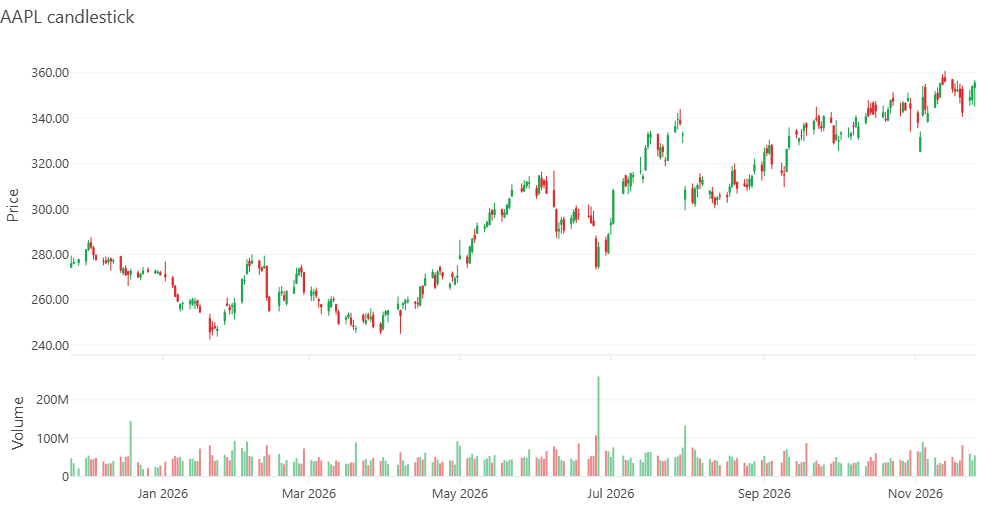

In [7]:
show("candlestick", charts.candlestick_chart(year, ticker=TICKER))

### Price with overlays
The moving averages show the trend. The shaded Bollinger band widens when the
price is more volatile.

Saved deliverables/walkthrough_output/price.html


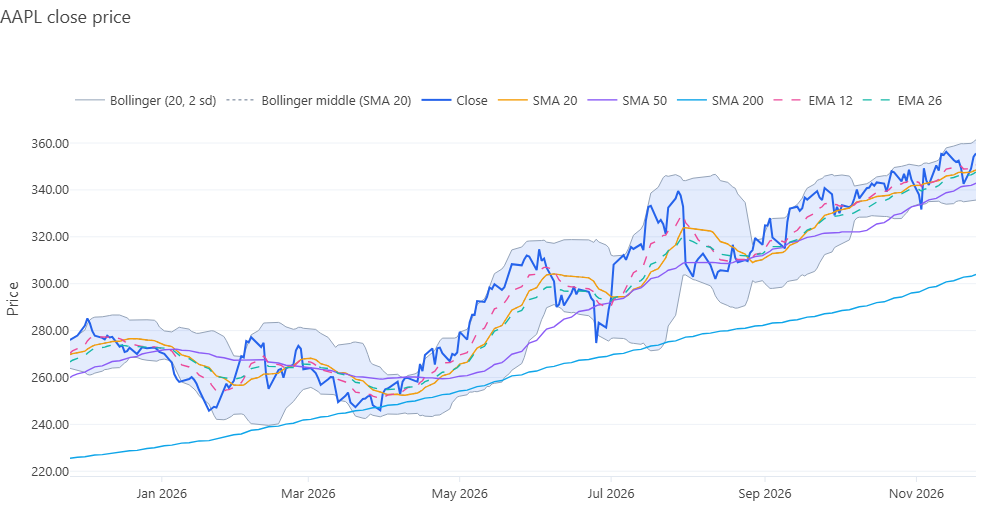

In [8]:
show(
    "price",
    charts.price_chart(
        year,
        ticker=TICKER,
        sma_windows=config.SMA_WINDOWS,
        ema_spans=config.EMA_SPANS,
        show_bollinger=True,
    ),
)

### Volume
Daily volume against its 20-day average.

Saved deliverables/walkthrough_output/volume.html


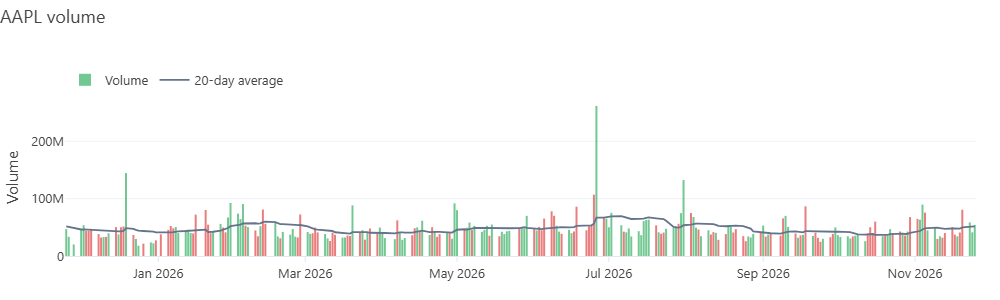

In [9]:
show("volume", charts.volume_chart(year, ticker=TICKER))

### RSI
Above 70 is conventionally called overbought, and below 30 oversold.

Saved deliverables/walkthrough_output/rsi.html


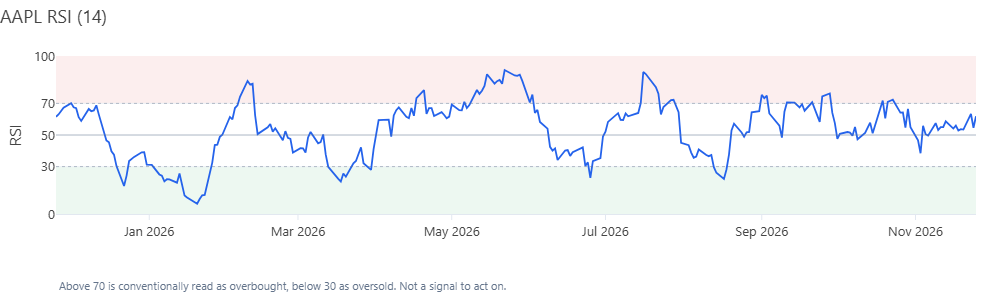

In [10]:
show("rsi", charts.rsi_chart(year, ticker=TICKER))

### MACD
The histogram is the gap between the MACD line and its signal line.

Saved deliverables/walkthrough_output/macd.html


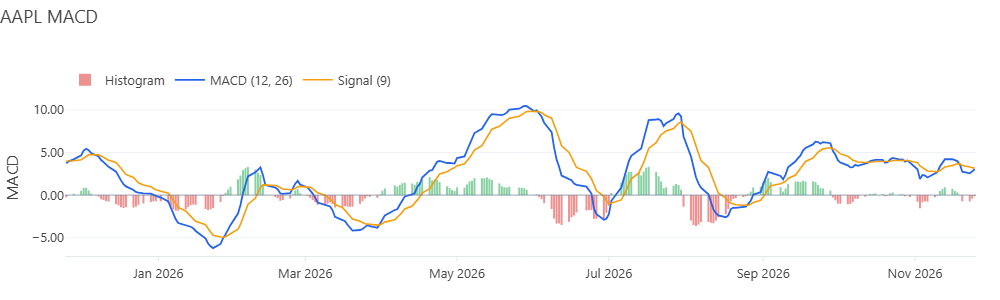

In [11]:
show("macd", charts.macd_chart(year, ticker=TICKER))

### Comparison
Every ticker starts at 100 on the first day they all traded, so growth can be
compared across currencies.

Saved deliverables/walkthrough_output/comparison.html


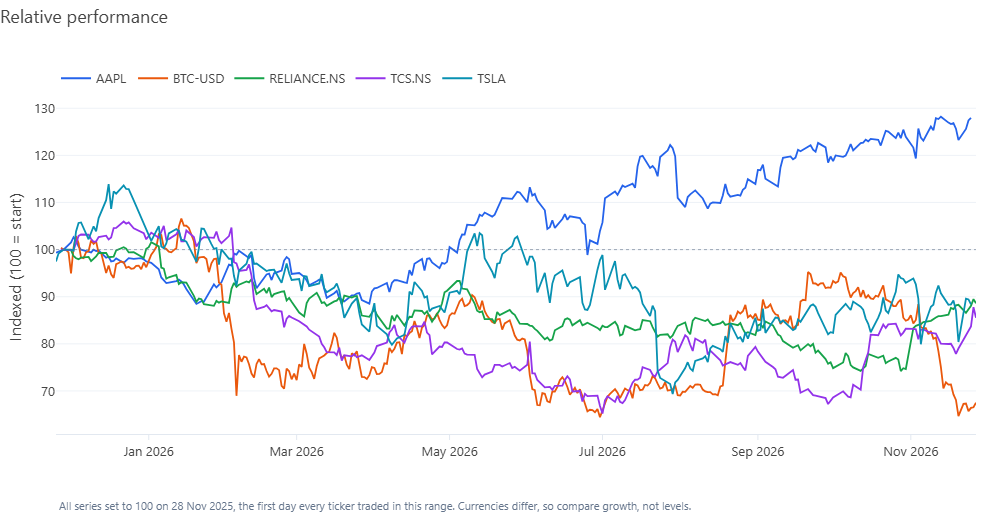

In [12]:
# The last year of each ticker's prices.
last_year = {symbol: summary_window(frame) for symbol, frame in frames.items()}
show("comparison", charts.comparison_chart(last_year))

### Monthly returns
One cell per calendar month over the full five years. The first and last
months may be part months.

Saved deliverables/walkthrough_output/monthly_returns.html


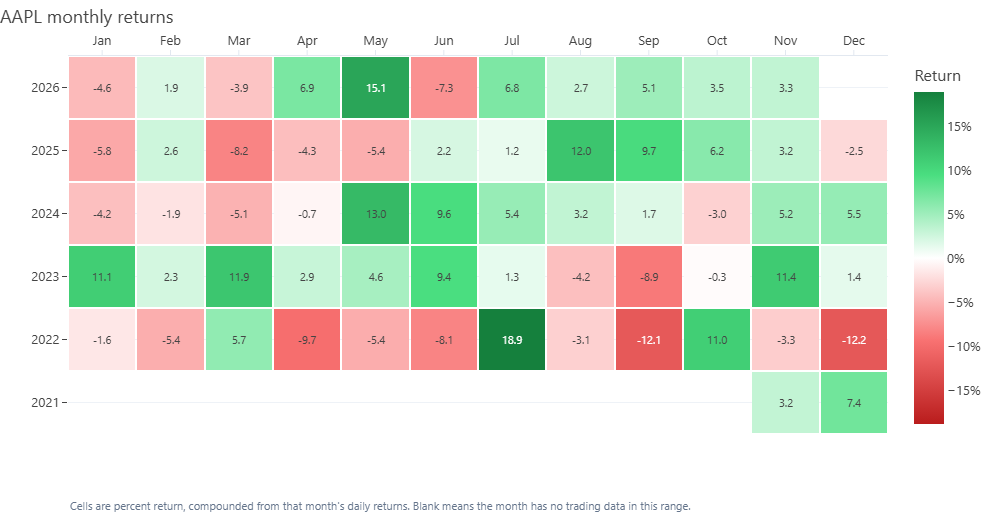

In [13]:
show("monthly_returns", charts.returns_heatmap(main["Close"], ticker=TICKER))

### Daily returns distribution
How often each size of daily move happened over the last year.

Saved deliverables/walkthrough_output/returns_distribution.html


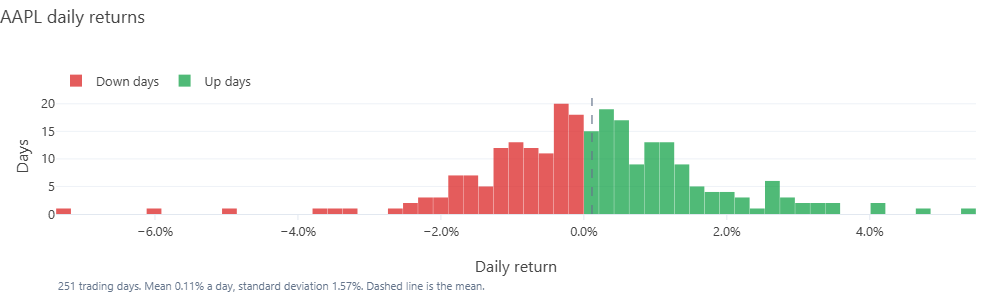

In [14]:
show(
    "returns_distribution",
    charts.returns_distribution_chart(year["Close"], ticker=TICKER),
)

### Correlation
Correlation of daily **returns**, over the days every ticker traded. Prices
that merely drift upwards together would look related when they are not.

237 common trading days
             AAPL  BTC-USD  RELIANCE.NS  TCS.NS  TSLA
AAPL         1.00     0.14         0.03    0.09  0.16
BTC-USD      0.14     1.00        -0.05   -0.02  0.33
RELIANCE.NS  0.03    -0.05         1.00    0.11  0.08
TCS.NS       0.09    -0.02         0.11    1.00  0.01
TSLA         0.16     0.33         0.08    0.01  1.00
Saved deliverables/walkthrough_output/correlation.html


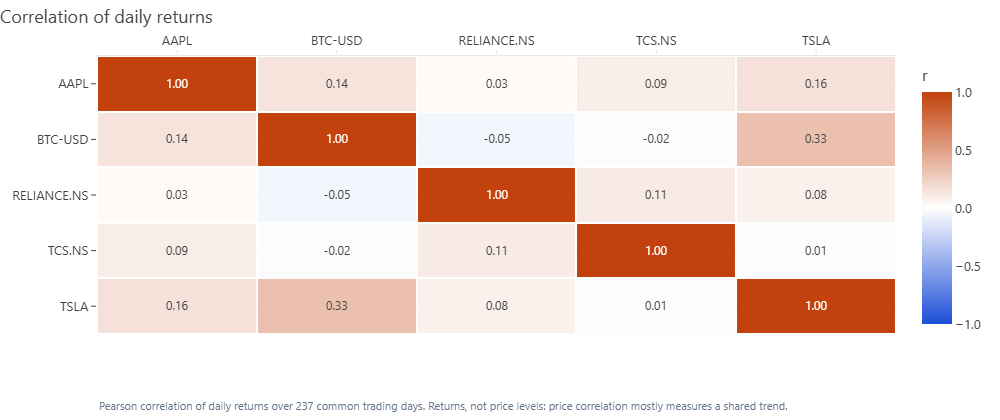

In [15]:
matrix, observations = charts.returns_correlation(last_year)
print(f"{observations} common trading days")
print(matrix.round(2).to_string())
show("correlation", charts.correlation_chart(last_year))

## 5. Combine into a dashboard

The KPI cards, the written summary and every chart above on one HTML page.
The interactive version, with slicers, is the Power BI report in `powerbi/`.

In [16]:
# The same KPI cards the PDF summaries print.
kpis = kpi_summary(year, info)
for card in kpis.cards:
    change = f"  ({card.delta})" if card.delta else ""
    print(f"{card.label:<11} {card.value}{change}")
print()
print(kpis.footnote)

# Build the page: a grid of cards, then each chart in the order shown above.
cards = "".join(
    '<div class="card">'
    f"<small>{html.escape(card.label)}</small>"
    f"<b>{html.escape(card.value)}</b>"
    f"<span>{html.escape(card.delta or '')}</span>"
    "</div>"
    for card in kpis.cards
)
panels = "".join(
    pio.to_html(figure, full_html=False, include_plotlyjs=False)
    for figure in FIGURES.values()
)
title = html.escape(f"{info.get('name') or TICKER} ({TICKER})")

page = f"""<!doctype html>
<html lang="en">
<head>
<meta charset="utf-8">
<meta name="viewport" content="width=device-width, initial-scale=1">
<title>{title}</title>
<script src="plotly.min.js"></script>
<style>
  body {{ font-family: Arial, sans-serif; max-width: 1100px; margin: 24px auto;
         padding: 0 16px; background: #fff; color: #0f172a; }}
  .cards {{ display: grid; grid-template-columns: repeat(4, 1fr); gap: 12px; }}
  .card {{ border: 1px solid #e2e8f0; border-radius: 8px; padding: 12px; }}
  .card small, .card b, .card span {{ display: block; }}
  .card b {{ font-size: 20px; }}
  p {{ color: #475569; }}
</style>
</head>
<body>
<h1>{title}</h1>
<div class="cards">{cards}</div>
<p>{html.escape(kpis.footnote)}</p>
<p>{html.escape(commentary(year))}</p>
{panels}
<p>{html.escape(config.DISCLAIMER)}</p>
</body>
</html>
"""

# plotly.min.js was written beside the chart files by show(), so the page
# works offline.
dashboard = OUTPUT_DIR / "dashboard.html"
dashboard.write_text(page, encoding="utf-8")
print(f"\nDashboard: {dashboard.relative_to(ROOT).as_posix()} ({len(FIGURES)} charts)")

Price       $355.58  (+0.43%)
52w high    $360.83
52w low     $243.42
YTD return  +31.25%
Market cap  $5.17T
P/E         39.60
Avg volume  43.75M
Volatility  24.95%

252 trading days, 25 Nov 2025 to 25 Nov 2026. Period return +28.83%. Volatility is annualised over this range on 252 periods a year; the 52-week range is from Yahoo.

Dashboard: deliverables/walkthrough_output/dashboard.html (9 charts)
